In [1]:
from pathlib import Path

csv_files = list(Path(".").glob("*.csv"))

for i, file in enumerate(csv_files):
    print(i, file.name)


0 DataCoSupplyChainDataset.csv


In [3]:
import pandas as pd

print("Total CSV files:", len(csv_files))


Total CSV files: 1


In [8]:
file_path = csv_files[0]

try:
    df = pd.read_csv(file_path, encoding="cp1252")
    print("Dataset loaded successfully using cp1252!")

except UnicodeDecodeError:
    df = pd.read_csv(file_path, encoding="latin1")
    print("Dataset loaded successfully using latin1!")

print("Dataset size:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())



Dataset loaded successfully using cp1252!
Dataset size: (180519, 53)

Column names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


# Select delivery-related columns

In [9]:
actual_col = "Days for shipping (real)"
scheduled_col = "Days for shipment (scheduled)"

actual = pd.to_numeric(df[actual_col], errors="coerce")
scheduled = pd.to_numeric(df[scheduled_col], errors="coerce")

print("Total records:", len(df))
print("Missing actual durations:", actual.isna().sum())
print("Missing scheduled durations:", scheduled.isna().sum())

print("\nActual delivery duration statistics:")
display(actual.describe())

print("\nScheduled delivery duration statistics:")
display(scheduled.describe())


Total records: 180519
Missing actual durations: 0
Missing scheduled durations: 0

Actual delivery duration statistics:


count    180519.000000
mean          3.497654
std           1.623722
min           0.000000
25%           2.000000
50%           3.000000
75%           5.000000
max           6.000000
Name: Days for shipping (real), dtype: float64


Scheduled delivery duration statistics:


count    180519.000000
mean          2.931847
std           1.374449
min           0.000000
25%           2.000000
50%           4.000000
75%           4.000000
max           4.000000
Name: Days for shipment (scheduled), dtype: float64

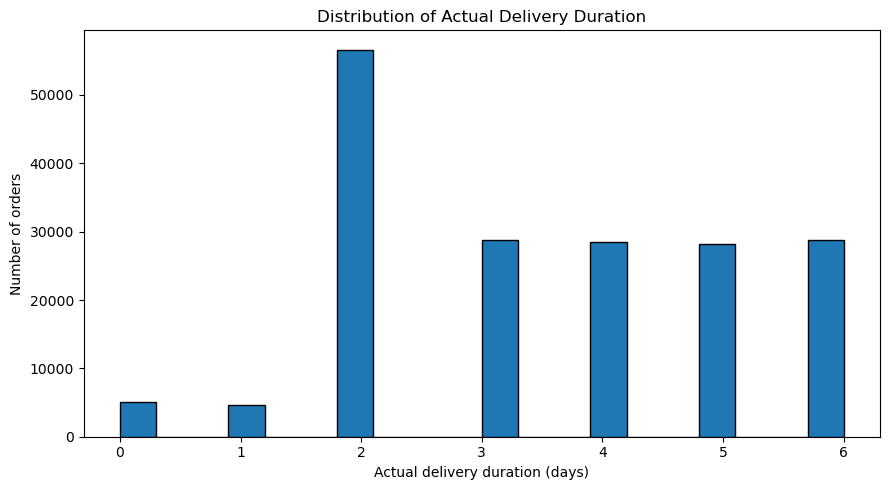

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(actual.dropna(), bins=20, edgecolor="black")
plt.xlabel("Actual delivery duration (days)")
plt.ylabel("Number of orders")
plt.title("Distribution of Actual Delivery Duration")
plt.tight_layout()
plt.show()


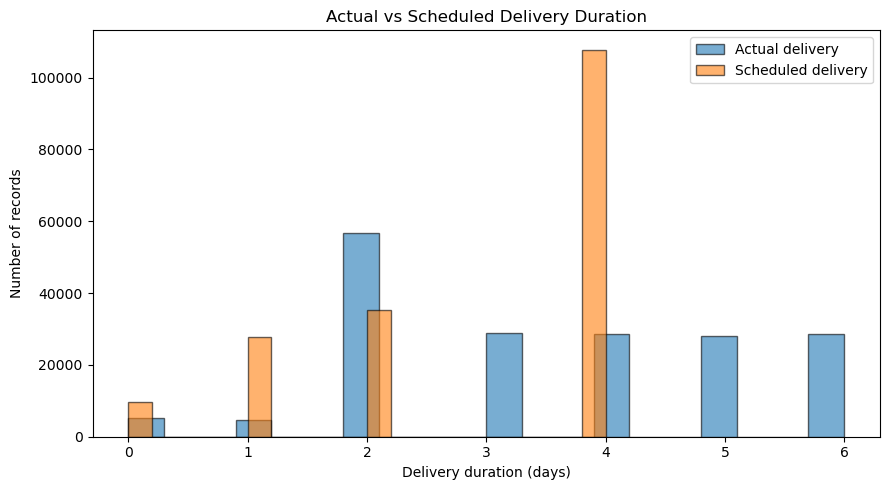

In [11]:

plt.figure(figsize=(9, 5))

plt.hist(actual.dropna(), bins=20, alpha=0.6,
         label="Actual delivery", edgecolor="black")
plt.hist(scheduled.dropna(), bins=20, alpha=0.6,
         label="Scheduled delivery", edgecolor="black")

plt.xlabel("Delivery duration (days)")
plt.ylabel("Number of records")
plt.title("Actual vs Scheduled Delivery Duration")
plt.legend()
plt.tight_layout()
plt.show()


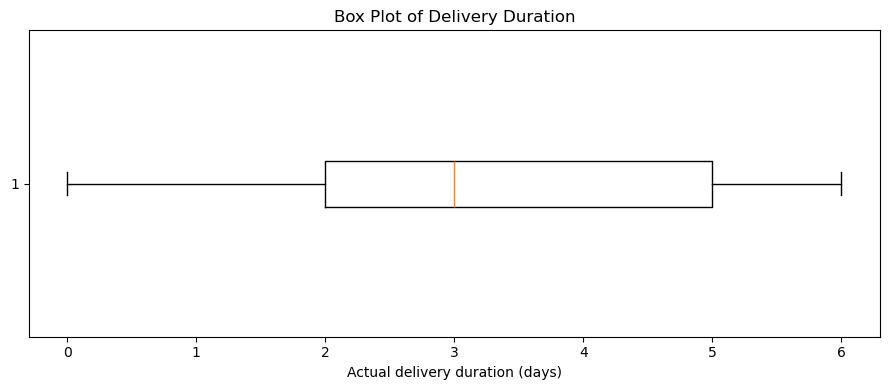

In [12]:

plt.figure(figsize=(9, 4))
plt.boxplot(actual.dropna(), vert=False)
plt.xlabel("Actual delivery duration (days)")
plt.title("Box Plot of Delivery Duration")
plt.tight_layout()
plt.show()


In [13]:

Q1 = actual.quantile(0.25)
Q3 = actual.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    actual.notna() &
    ((actual < lower_bound) | (actual > upper_bound))
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential unusual records:", outlier_mask.sum())

display(
    df.loc[outlier_mask, [
        "Order Id",
        "Days for shipping (real)",
        "Days for shipment (scheduled)",
        "Delivery Status",
        "Shipping Mode"
    ]].head(20)
)


Q1: 2.0
Q3: 5.0
IQR: 3.0
Lower bound: -2.5
Upper bound: 9.5
Potential unusual records: 0


,Order Id,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Shipping Mode


In [14]:

analysis = pd.DataFrame({
    "actual_days": actual,
    "scheduled_days": scheduled
})

analysis["delay_days"] = (
    analysis["actual_days"] - analysis["scheduled_days"]
)

print("Orders delivered later than scheduled:",
      (analysis["delay_days"] > 0).sum())

print("Orders delivered on schedule:",
      (analysis["delay_days"] == 0).sum())

print("Orders delivered earlier than scheduled:",
      (analysis["delay_days"] < 0).sum())

display(analysis["delay_days"].describe())


Orders delivered later than scheduled: 103400
Orders delivered on schedule: 33753
Orders delivered earlier than scheduled: 43366


count    180519.000000
mean          0.565807
std           1.490966
min          -2.000000
25%           0.000000
50%           1.000000
75%           1.000000
max           4.000000
Name: delay_days, dtype: float64

In [15]:

from pathlib import Path

output_dir = Path("delivery_duration_results")
output_dir.mkdir(exist_ok=True)

# Export only relevant columns; avoid customer personal data
results = df.loc[outlier_mask, [
    "Order Id",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Shipping Mode"
]].copy()

results.to_csv(
    output_dir / "potential_unusual_deliveries.csv",
    index=False
)

summary = f"""
Delivery Duration Analysis

Total records: {len(df)}
Valid actual durations: {actual.notna().sum()}
Missing actual durations: {actual.isna().sum()}
Mean duration: {actual.mean():.2f} days
Median duration: {actual.median():.2f} days
Minimum duration: {actual.min()} days
Maximum duration: {actual.max()} days
IQR lower bound: {lower_bound:.2f}
IQR upper bound: {upper_bound:.2f}
Potential unusual records: {outlier_mask.sum()}
Delivered later than scheduled: {(analysis['delay_days'] > 0).sum()}
Delivered on schedule: {(analysis['delay_days'] == 0).sum()}
Delivered earlier than scheduled: {(analysis['delay_days'] < 0).sum()}
"""

(output_dir / "analysis_summary.txt").write_text(
    summary, encoding="utf-8"
)

print(summary)
print("Analysis files saved in:", output_dir.resolve())



Delivery Duration Analysis

Total records: 180519
Valid actual durations: 180519
Missing actual durations: 0
Mean duration: 3.50 days
Median duration: 3.00 days
Minimum duration: 0 days
Maximum duration: 6 days
IQR lower bound: -2.50
IQR upper bound: 9.50
Potential unusual records: 0
Delivered later than scheduled: 103400
Delivered on schedule: 33753
Delivered earlier than scheduled: 43366

Analysis files saved in: C:\Users\HP\Internship\delivery_duration_results
